# Machine Learning: SIS-2 — Part 1: Exploratory Data Analysis

## 1. Setup and data loading

In [2]:

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore")

TARGET = "Diabetes_binary"
PALETTE = ["#5B0D51", "#FF33B4"]          
CLASS_NAMES = {0: "No diabetes", 1: "Diabetes"}

In [3]:
# Load the dataset from the local CSV file
df = pd.read_csv(r"C:\KBTU\ML\diabetes_binary_health_indicators_BRFSS2015.csv")
print("Loaded:", df.shape)

Loaded: (253680, 22)


The dataset was loaded from the local CSV file. It has 22 columns in total (21 features + the target) and there is no ID column, so there is nothing to drop before modelling.

## 2. Dataset description

In [4]:
n_rows, n_cols = df.shape
print(f"Rows: {n_rows:,}")
print(f"Columns: {n_cols}")
print()
df.info()

Rows: 253,680
Columns: 22

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253

In [5]:
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


**Interpretation.** The data shape check shows 253,680 rows and 22 columns. All columns are numeric, there are no missing values, and the first rows confirm that the target and ordinal variables are already encoded as integers. I did not need to convert any column types before analysis.

In [6]:
# Feature dictionary: group features by type 
numeric_cols = ["BMI", "MentHlth", "PhysHlth"]
ordinal_cols = ["GenHlth", "Age", "Education", "Income"]
binary_cols = [c for c in df.columns if c not in numeric_cols + ordinal_cols + [TARGET]]

kind = {**{c: "numeric" for c in numeric_cols}, **{c: "ordinal" for c in ordinal_cols},
        **{c: "binary" for c in binary_cols}, TARGET: "target"}

feature_table = pd.DataFrame({
    "type": pd.Series(kind),
    "n_unique": df.nunique(),
    "min": df.min(), "max": df.max()
}).loc[df.columns]
feature_table

,type,n_unique,min,max
Diabetes_binary,target,2,0.0,1.0
HighBP,binary,2,0.0,1.0
HighChol,binary,2,0.0,1.0
CholCheck,binary,2,0.0,1.0
BMI,numeric,84,12.0,98.0
Smoker,binary,2,0.0,1.0
Stroke,binary,2,0.0,1.0
HeartDiseaseorAttack,binary,2,0.0,1.0
PhysActivity,binary,2,0.0,1.0
Fruits,binary,2,0.0,1.0


**Interpretation.** This dataset contains 253,680 survey respondents from the CDC BRFSS 2015 sample, with 21 features and one binary target, `Diabetes_binary`. The target is coded as 0 = no diabetes and 1 = diabetes, and the feature columns are already numerically encoded.

The features split into three groups:

- 14 binary indicators such as `HighBP`, `PhysActivity`, and `DiffWalk`
- 4 ordinal scale variables: `GenHlth`, `Age`, `Education`, and `Income`
- 3 numeric variables: `BMI`, `MentHlth`, and `PhysHlth`

This split is useful because it tells me how to visualise the data and how to prepare the features for modelling in Part 2.

In [7]:
df[numeric_cols].describe().transpose().style.format("{:.2f}")

,count,mean,std,min,25%,50%,75%,max
BMI,253680.00,28.38,6.61,12.00,24.00,27.00,31.00,98.00
MentHlth,253680.00,3.18,7.41,0.00,0.00,0.00,2.00,30.00
PhysHlth,253680.00,4.24,8.72,0.00,0.00,0.00,3.00,30.00


**Interpretation.** The summary statistics show that `BMI` is around 28 on average, with a long right tail and some very high values. `MentHlth` and `PhysHlth` are counts from 0 to 30, and their medians are 0, which means most respondents report no bad days but a smaller group reports many. This pattern is skewed and zero-inflated, so scaling and a transformation for the count-like variables are important before distance-based models such as KNN and SVM.

## 3. Data quality checks

In [8]:
missing = df.isnull().sum()
print("Total missing values:", int(missing.sum()))
print(missing[missing > 0] if missing.sum() else "No Missing Values Found")

n_dup = df.duplicated().sum()
print(f"\nDuplicated rows: {n_dup:,} ({n_dup / len(df):.2%} of the data)")

Total missing values: 0
No Missing Values Found

Duplicated rows: 24,206 (9.54% of the data)


**Interpretation.** There are 24,206 duplicated rows, which is 9.54% of the dataset. I kept them because they are different people who gave the same answers, and this is common in survey data with repeated health profiles. These duplicates do not create missing data, but they can still affect how strongly some patterns appear in the training set.

## 4. Target distribution (class imbalance)

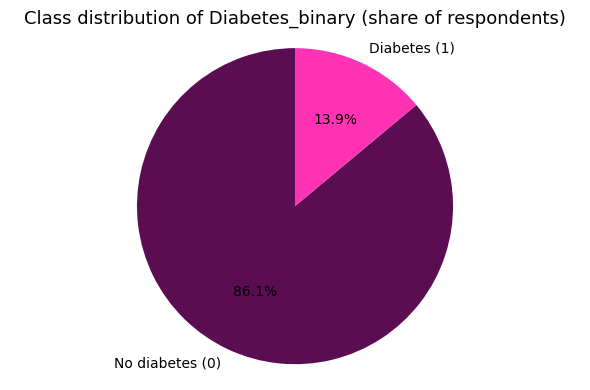

In [9]:
plt.figure(figsize=(6, 4))
plt.pie(
    df[TARGET].value_counts().sort_index(),
    labels=['No diabetes (0)', 'Diabetes (1)'],
    startangle=90,
    autopct='%1.1f%%',
    colors=PALETTE
)
plt.title("Class distribution of Diabetes_binary (share of respondents)", fontsize=13)
plt.axis('equal')
plt.tight_layout()
plt.show()

*Figure 1. Class distribution of `Diabetes_binary` in the dataset.*

The target is strongly imbalanced: 218,334 respondents have no diabetes (86.1%) and 35,346 have diabetes (13.9%). This means the positive class is much smaller, so accuracy alone would not be a good measure of model quality.

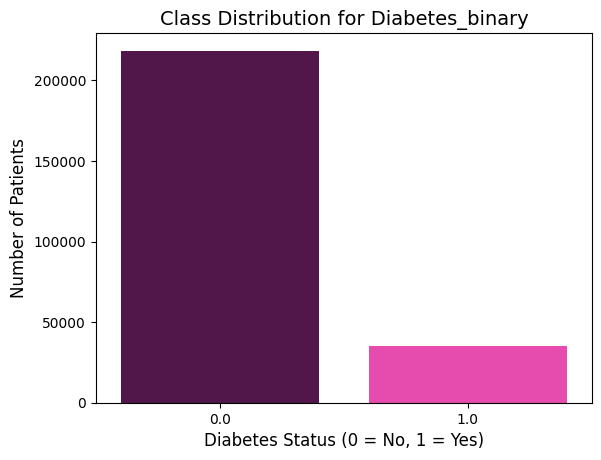

In [10]:

sns.countplot(data=df, x=TARGET, palette=PALETTE, legend=False, hue = TARGET)

plt.title(f"Class Distribution for {TARGET}", fontsize=14)
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)", fontsize=12) 
plt.ylabel("Number of Patients", fontsize=12)

plt.show()

*Figure 2. Count plot of `Diabetes_binary`.*

The bar chart confirms the same pattern as the pie chart: class 0 appears much more often than class 1, with a ratio of roughly 6.2 to 1. This matters because a model that always predicts "no diabetes" could look good on accuracy while missing the positive cases we care about.

## 5. Features vs. target

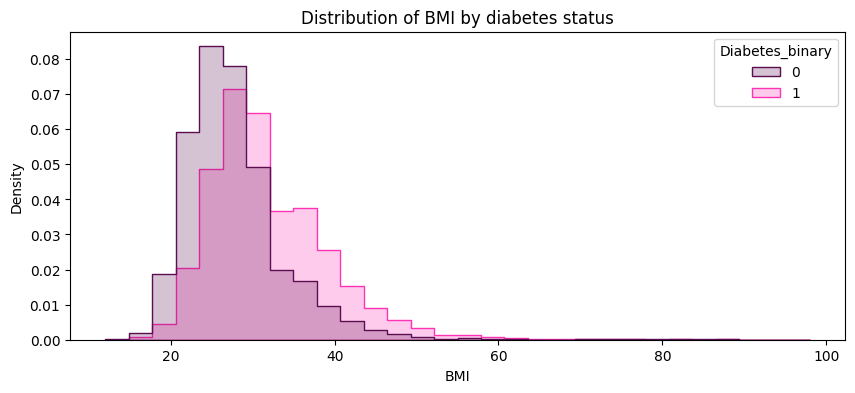

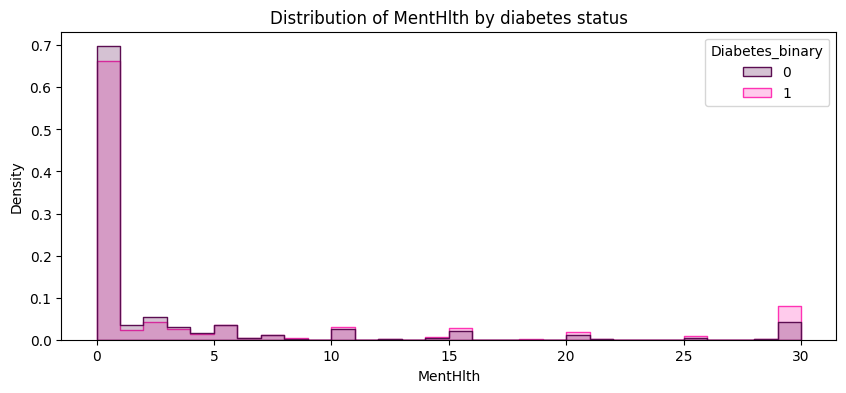

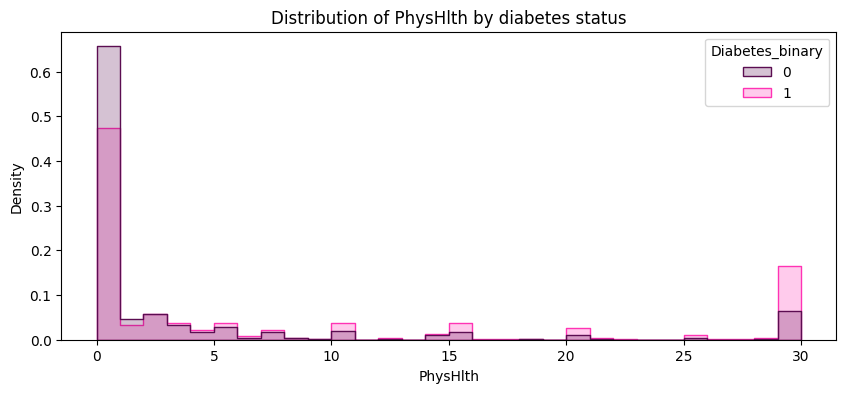

In [11]:
# Numeric Features vs. Target

for col in numeric_cols:
    plt.figure(figsize=(10, 4))
    sns.histplot(data=df, x=col,hue=TARGET, hue_order=[0, 1], palette=PALETTE,
             bins=30, stat="density", common_norm=False, element="step")
    plt.title(f"Distribution of {col} by diabetes status")
    plt.xlabel(col)
    plt.ylabel("Density")
    plt.show()

*Figure 3. Density distributions of `BMI`, `MentHlth`, and `PhysHlth` by diabetes status.*

The y-axis is density, not a raw count, so the area under each class is 1. This makes the shapes of the two distributions easier to compare even though the target is imbalanced, and it shows that the diabetes group is shifted toward higher `BMI` values and more bad-health days.

- `BMI`: both classes are right-skewed, but the diabetes group is shifted toward higher values, which matches the idea that higher BMI is associated with diabetes.
- `MentHlth` and `PhysHlth`: both variables are highly zero-inflated, with many respondents reporting 0 bad days. The diabetes group has more respondents at higher values, especially for `PhysHlth`, which suggests these variables may be useful but need careful scaling.

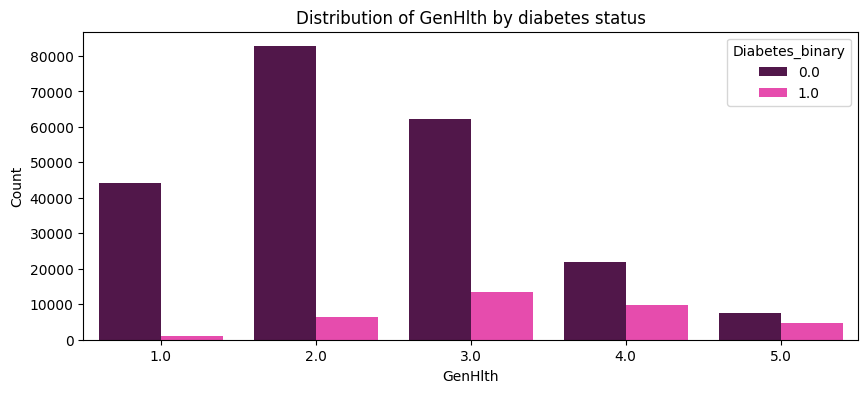

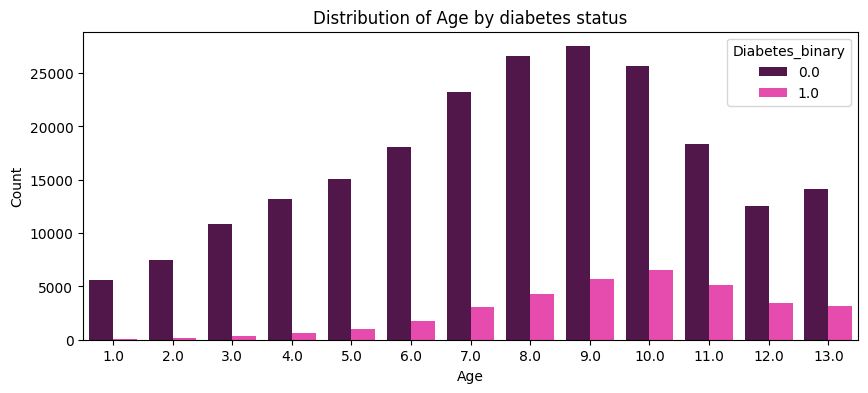

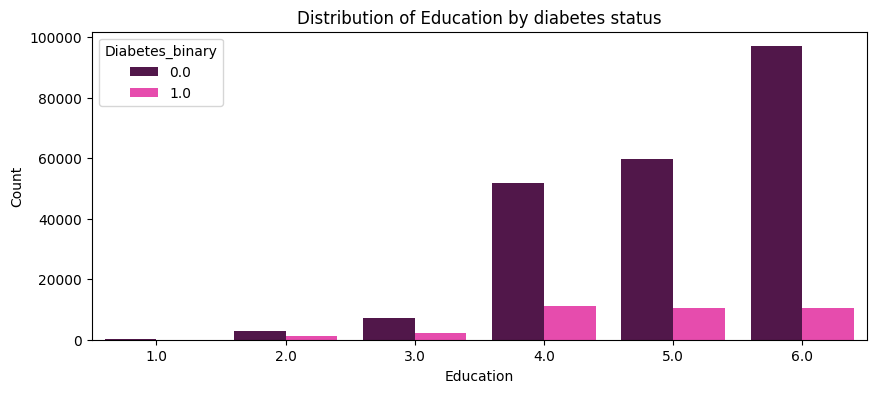

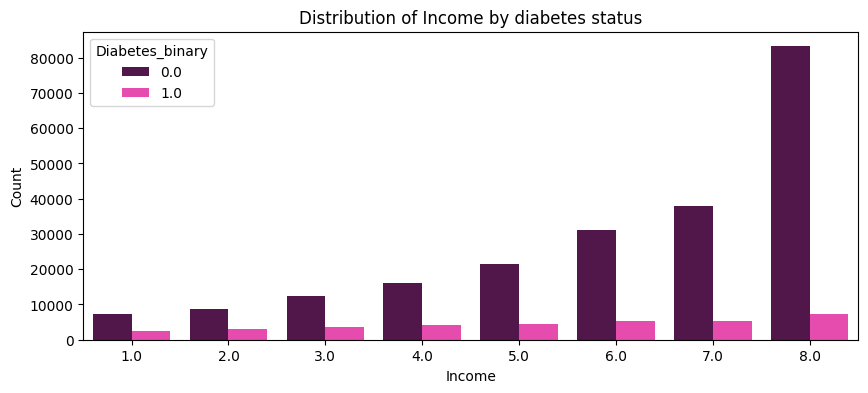

In [12]:
# Ordinal Features vs. Target

for col in ordinal_cols:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df, x=col, hue=TARGET, palette=PALETTE)
    plt.title(f"Distribution of {col} by diabetes status")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

*Figure 4. Distribution of ordinal feature levels by diabetes status.*

The bar plots show counts, so the positive class looks small in every category because the dataset is imbalanced. To compare feature strength, I need to look at the share of diabetes within each level rather than just the raw heights of the bars.

- `GenHlth`: the diabetes share is clearly larger at worse health levels, especially from 4 to 5.
- `Age`: diabetes is rare in the youngest groups and becomes much more common in older groups.
- `Education` and `Income`: lower education and lower income levels have a larger share of diabetes, which matches the health-risk pattern in the data.

These patterns suggest that poor health, older age, and lower socio-economic status are associated with diabetes in this sample.

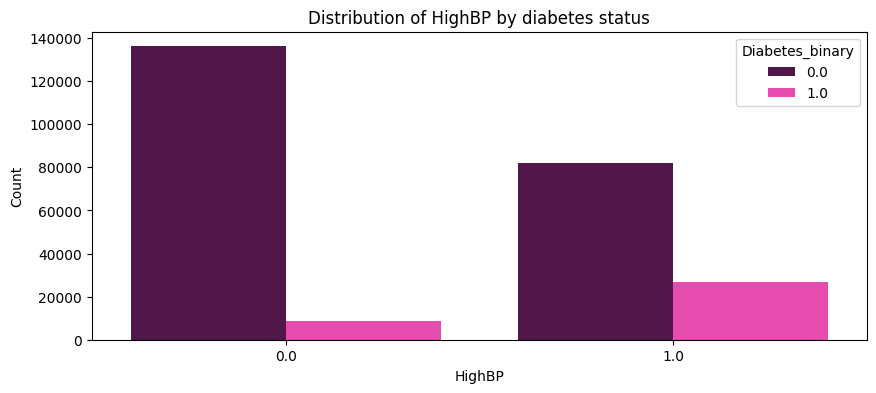

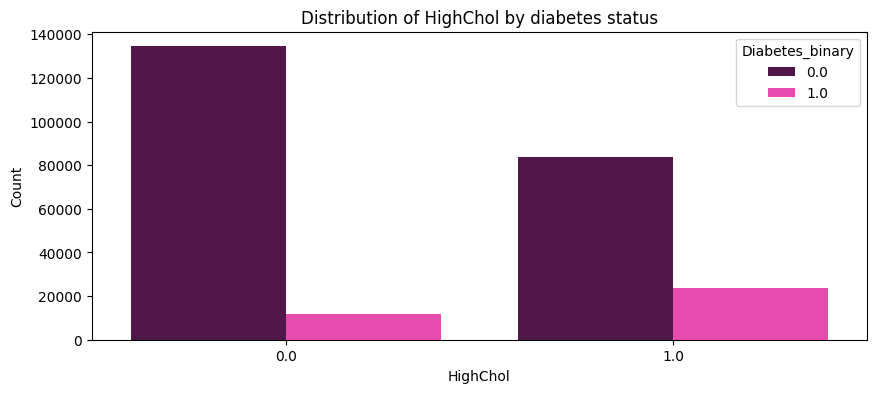

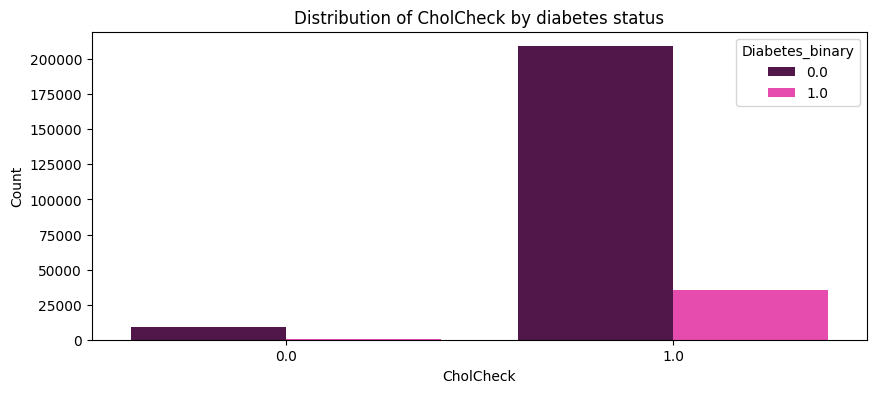

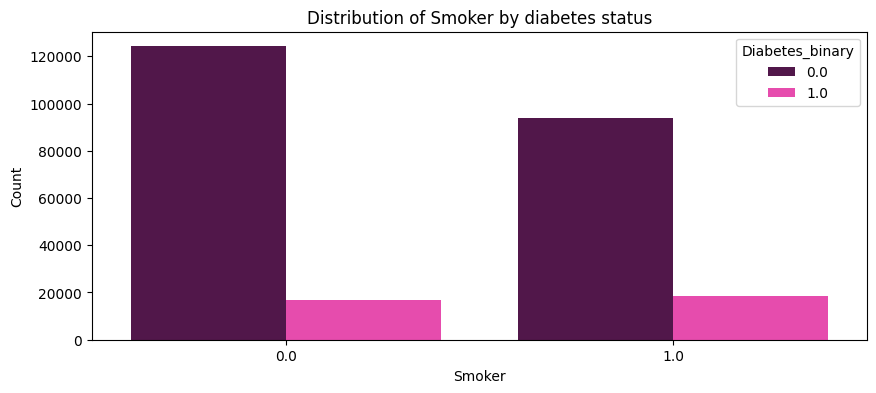

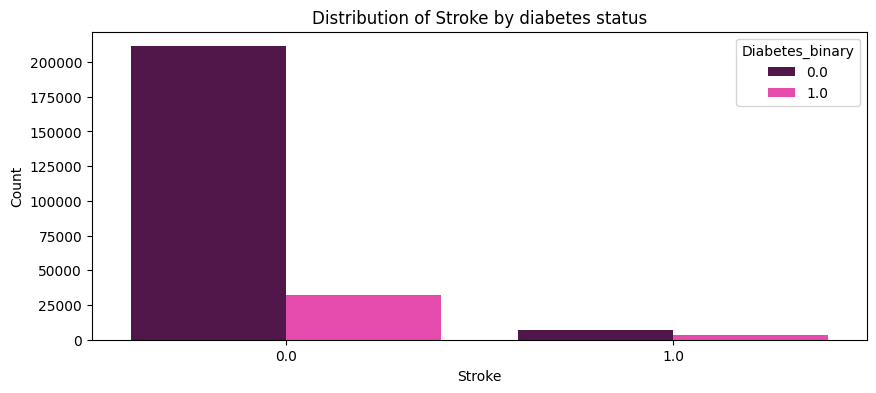

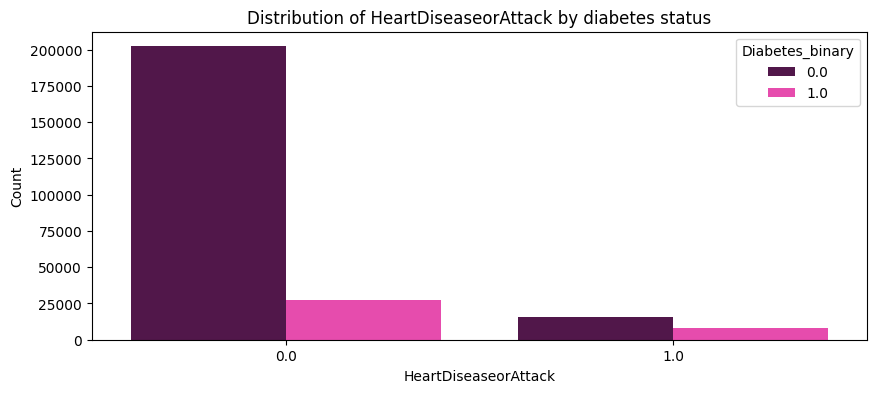

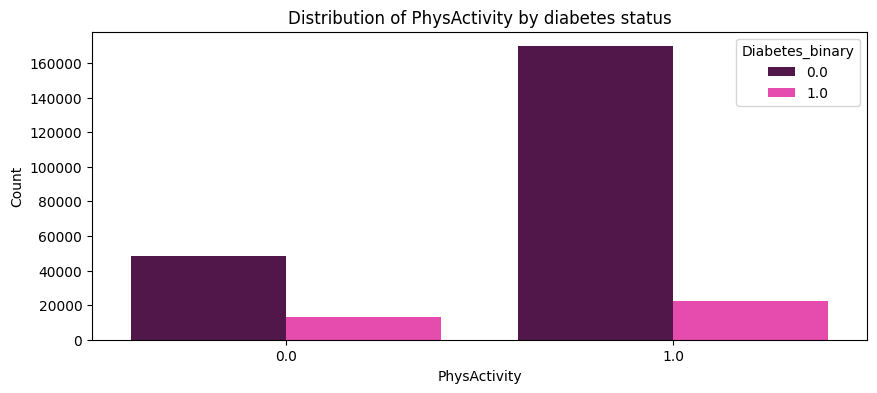

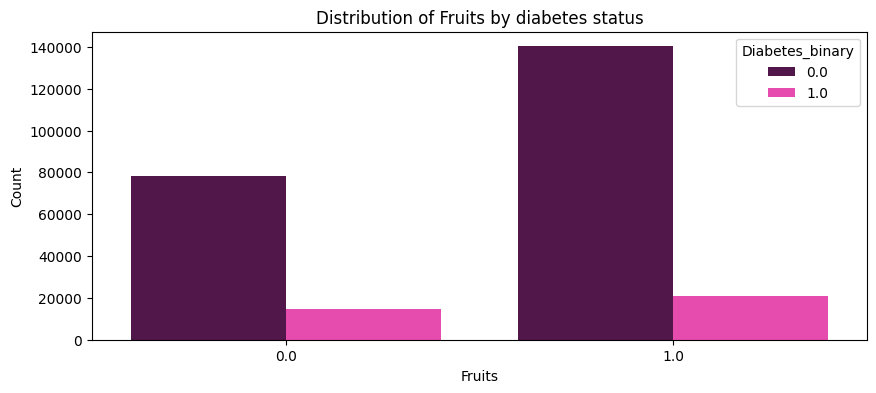

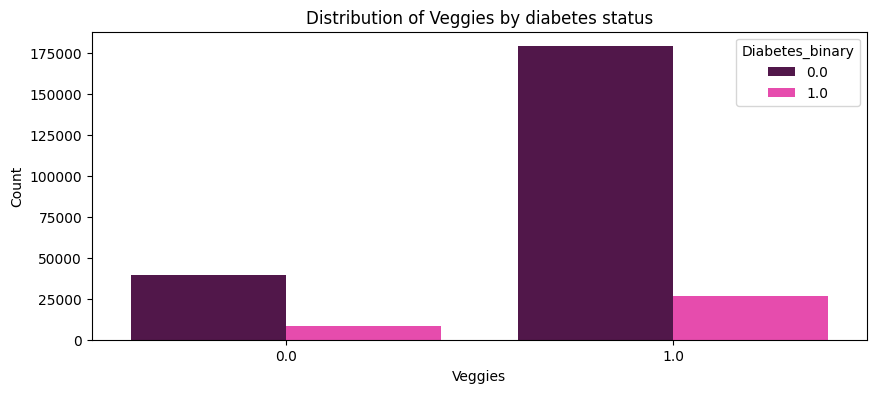

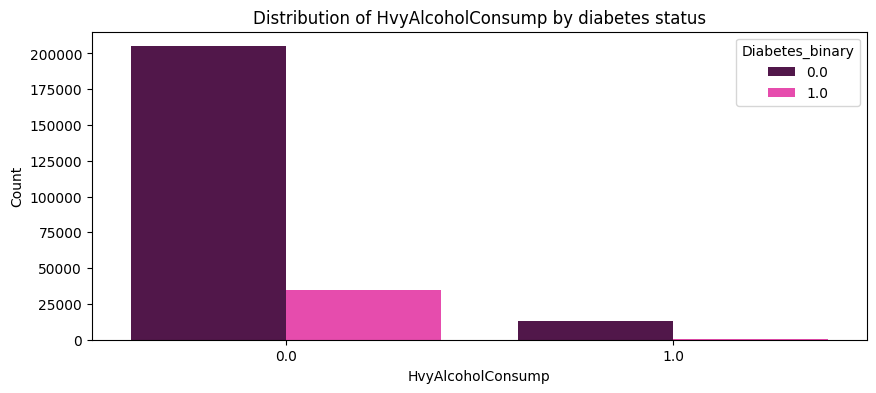

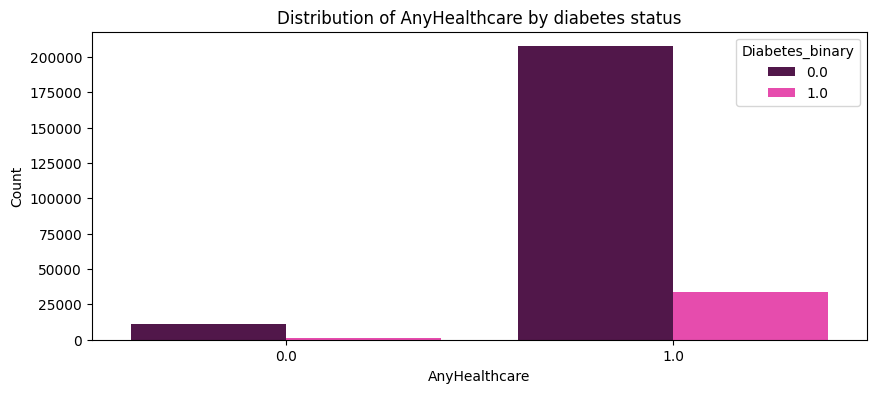

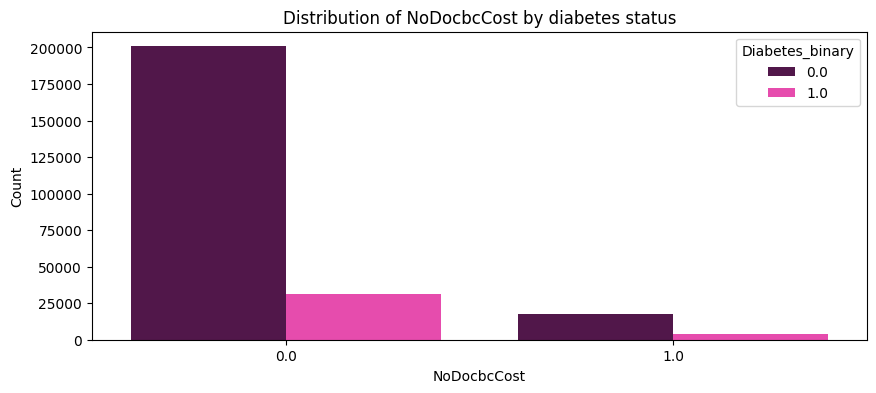

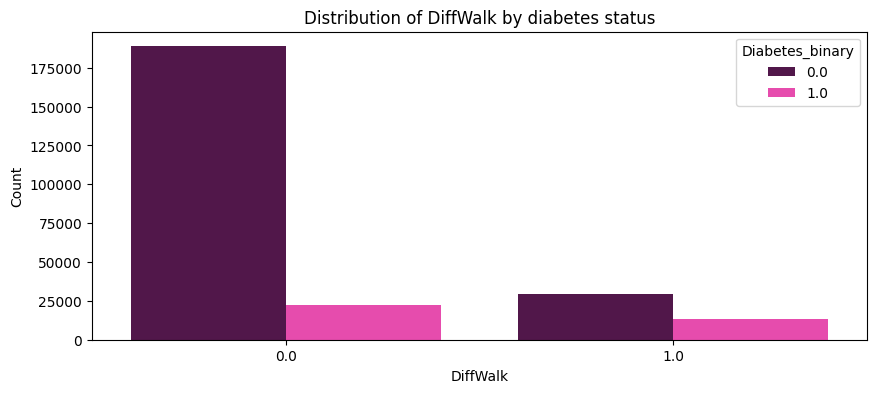

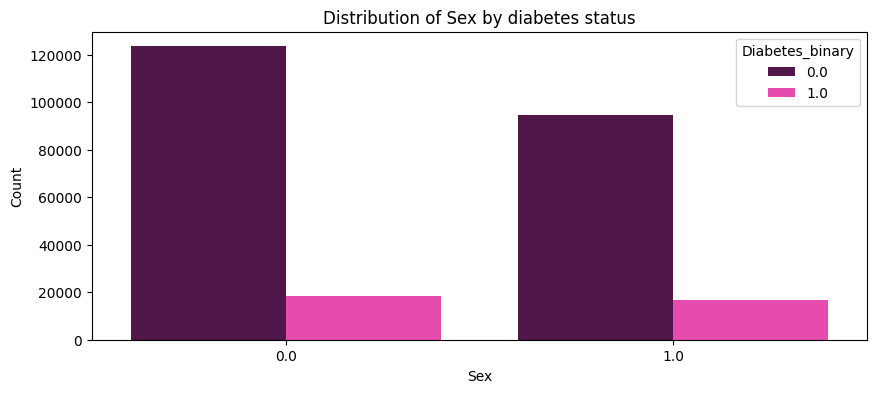

In [13]:
# Binary Features vs. Target

for col in binary_cols:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df, x=col, hue=TARGET, palette=PALETTE)
    plt.title(f"Distribution of {col} by diabetes status")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

*Figure 5. Binary feature distributions by diabetes status.*

These plots also show counts, so the main comparison is the ratio between the diabetes and no-diabetes groups within each feature value. This helps me see which binary indicators are more strongly associated with diabetes.

- Stronger positive associations appear for `HighBP`, `HighChol`, `DiffWalk`, `HeartDiseaseorAttack`, and `Stroke`.
- `PhysActivity` looks protective, because respondents who are physically active have a lower diabetes share.
- Weak or mixed signals appear for `Fruits`, `Veggies`, `AnyHealthcare`, `NoDocbcCost`, `Sex`, `CholCheck`, and `Smoker`.

This is an observational survey pattern, not proof of causation, but it helps decide which variables are likely to be most useful in the models.

## 6. Correlation analysis

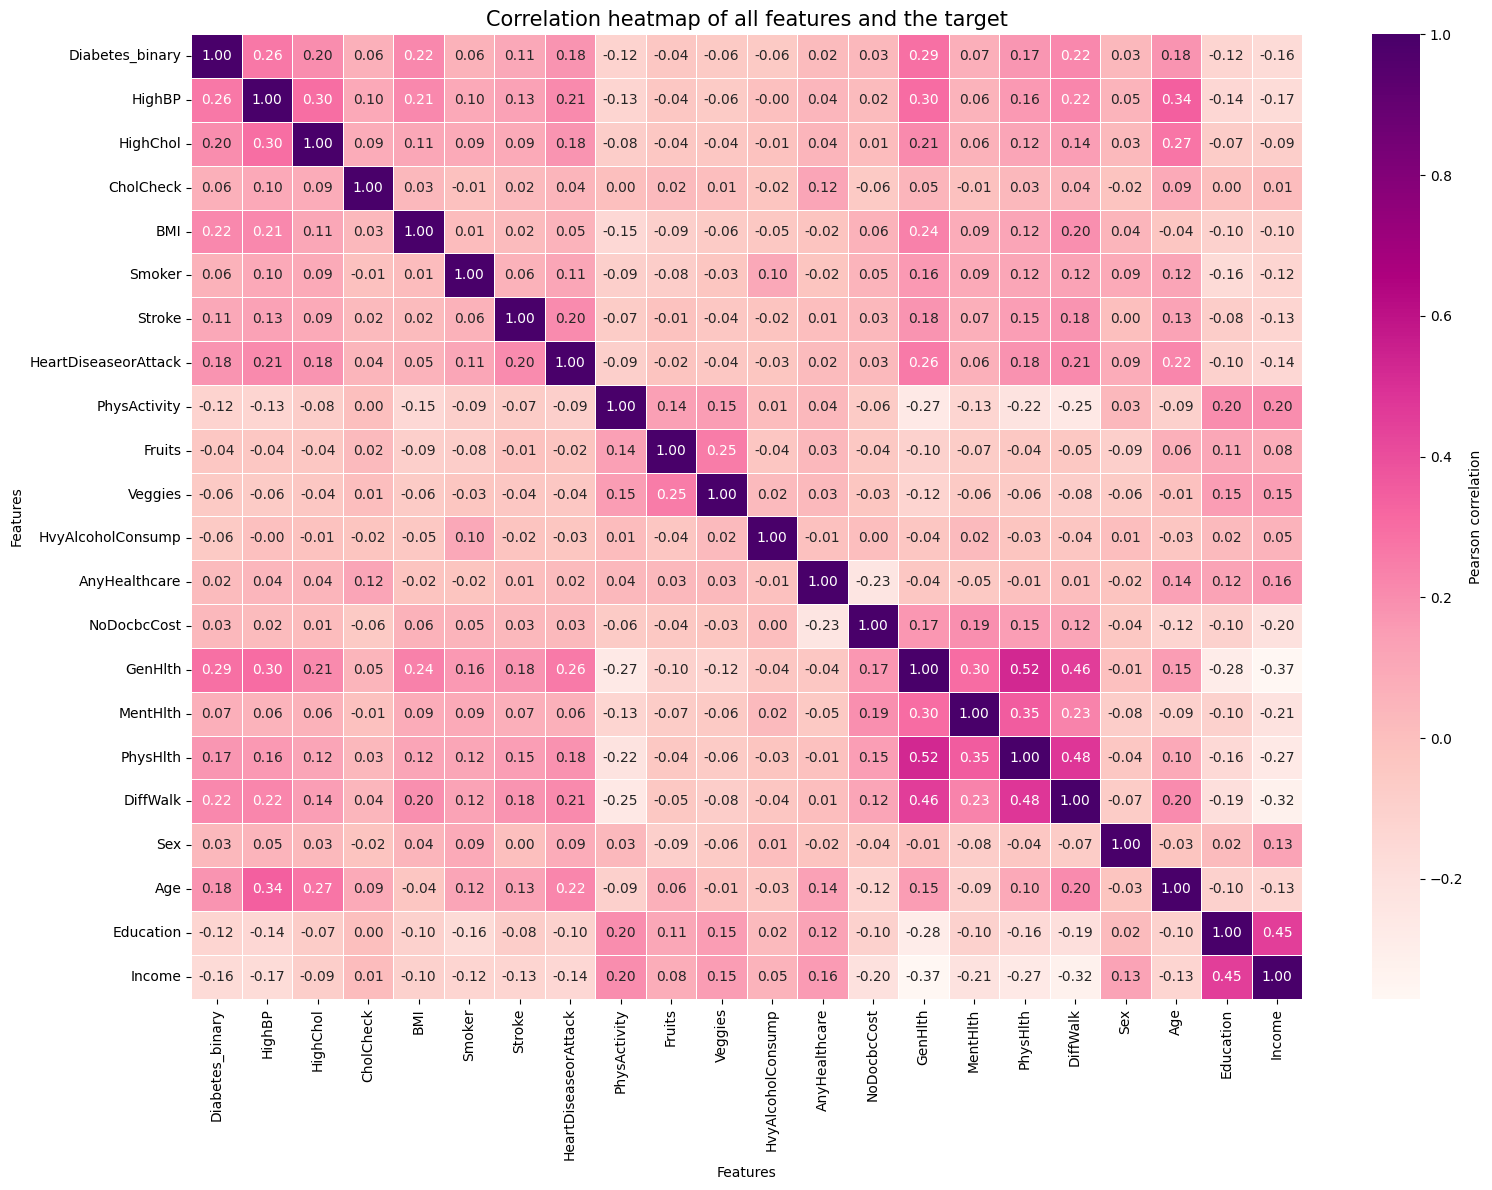

In [ ]:
corr = df.corr()
        
plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, fmt=".2f",
            cmap="RdPu", linewidths=0.4, linecolor="white", cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation heatmap of all features and the target", fontsize=15)
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

*Figure 6. Pearson correlation heatmap of all features and the target.*

The strongest relationships are mainly between health-related features such as `GenHlth`, `PhysHlth`, and `DiffWalk`, and also between `Income` and `Education`. Most correlations are weak to moderate, so there is no major sign of severe multicollinearity in the dataset.

This is useful because it tells me that the model should not be badly distorted by highly redundant predictors, even though some variables are clearly related to each other.

# Machine Learning: SIS-2 — Part 2: Preprocessing

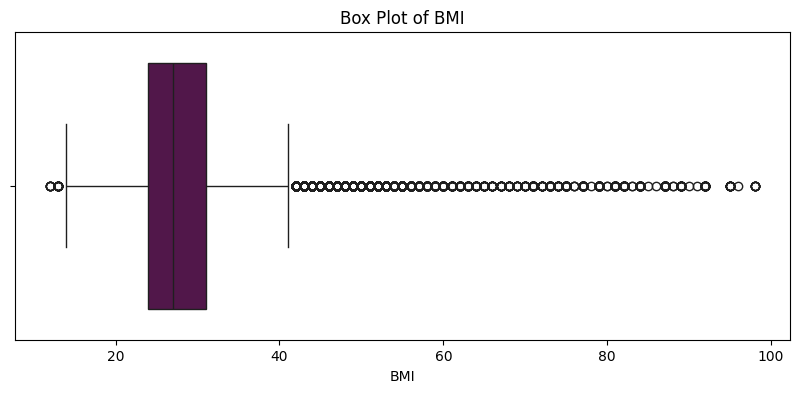

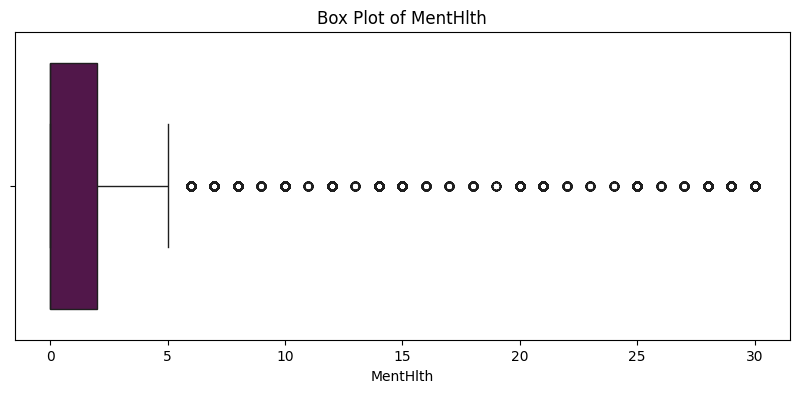

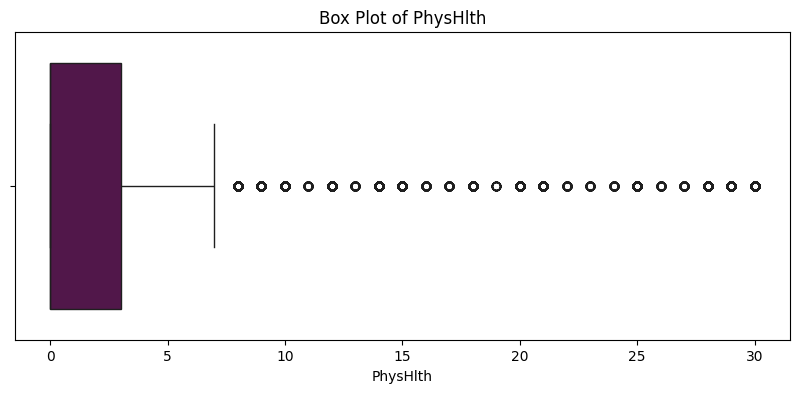

In [15]:
# Finding Outliers

for col in numeric_cols:
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=df, x=col, palette=PALETTE)
    plt.title(f'Box Plot of {col}')
    plt.xlabel(col)
    plt.show()

*Figure 7. Box plots of `BMI`, `MentHlth`, and `PhysHlth` for outlier checking.*

The box plots show that `BMI` has some very high values, and the count-like variables are mostly zero with a few large values. I did not delete these records because they come from real survey responses, and removing them would reduce useful information in the positive class.

I handled the extreme values in a controlled way instead: I clipped `BMI` at the 1st and 99th percentiles and used `log1p` on `MentHlth` and `PhysHlth` before scaling. This keeps the information while limiting the impact of the long right tail.

In [16]:
# Train and Test Split

from sklearn.model_selection import train_test_split
X = df.drop(columns=[TARGET])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print(f"Training set size: {X_train.shape} , Test set size: {X_test.shape}")

Training set size: (202944, 21) , Test set size: (50736, 21)


**Train/test split.** I split the data into 80% training and 20% testing using `stratify=y`, so both parts keep the same class ratio. This matters because the dataset has about 86% no-diabetes and 14% diabetes, and without stratification the test set could contain too few positive cases. I kept the same random seed each time (`random_state=42`) so the split is reproducible, and I did not use the test set for tuning or preprocessing decisions.

In [17]:
X_train = X_train.copy()
X_test = X_test.copy()

before = X_train[numeric_cols].copy()

bmi_low, bmi_high = X_train["BMI"].quantile([0.01, 0.99])
X_train["BMI"] = X_train["BMI"].clip(bmi_low, bmi_high)
X_test["BMI"] = X_test["BMI"].clip(bmi_low, bmi_high)


for col in ["MentHlth", "PhysHlth"]:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])

print(f"BMI clipped to [{bmi_low:.1f}, {bmi_high:.1f}]")
print("Skewness before:\n", before.skew().round(2))
print("Skewness after:\n", X_train[numeric_cols].skew().round(2))

BMI clipped to [18.0, 50.0]
Skewness before:
 BMI         2.11
MentHlth    2.72
PhysHlth    2.20
dtype: float64
Skewness after:
 BMI         1.08
MentHlth    1.52
PhysHlth    1.24
dtype: float64


**Outlier handling.** I clipped `BMI` at the 1st and 99th percentiles and used `log1p` on `MentHlth` and `PhysHlth` before scaling. This reduces the effect of extreme values while keeping the original survey information, which is important because these variables are strongly associated with health risk in this dataset. The goal was to reduce skewness without deleting valid rows or leaking test information into the training process.

In [18]:
# Preprocessing and Scaling

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

numerical_preprocessor = StandardScaler()
features = X_train.columns
preprocessor = ColumnTransformer(
    [('standard_scaler', numerical_preprocessor, features)]
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)


**Scaling.** I used `StandardScaler` on the feature matrix, which standardizes each column to mean 0 and standard deviation 1. This is important because the features are on different scales; for example, `BMI` is around 28 while binary variables are only 0 or 1. The scaler was fitted only on the training data and then applied to the test set, which prevents data leakage from the test set into the model.

,Before SMOTE,After SMOTE
Diabetes_binary,,
No diabetes,174667,174667
Diabetes,28277,174667


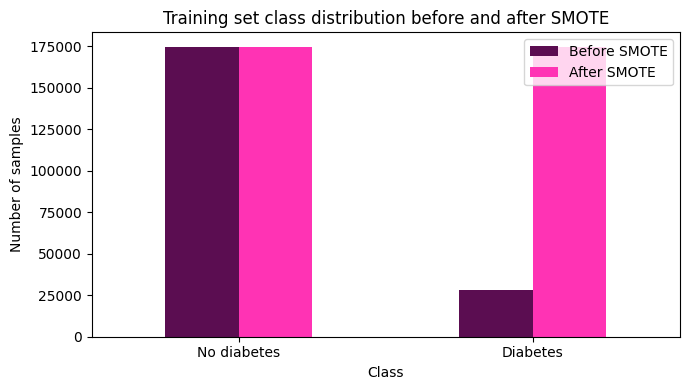

In [ ]:
# SMOTE for Disbalance Handling
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)   # ТОЛЬКО train

counts = pd.DataFrame({
    "Before SMOTE": y_train.value_counts().sort_index(),
    "After SMOTE": pd.Series(y_train_res).value_counts().sort_index(),
}).rename(index=CLASS_NAMES)
display(counts)

counts.plot(kind="bar", figsize=(7, 4), color=PALETTE, rot=0)
plt.title("Training set class distribution before and after SMOTE")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.tight_layout(); plt.show()


*Figure 8. Training set class distribution before and after SMOTE.*

The plot compares the class counts in the training set before and after SMOTE. The positive class was increased from 28,277 to 174,667 cases, so the model was trained on a balanced target distribution rather than the original 86/14 split.

This helps the classifiers learn the minority class, but it has an important limitation: SMOTE creates synthetic samples between nearby neighbours, and on binary or ordinal features those synthetic values can become non-integer. That is a practical issue for this dataset because many variables are 0/1 or ordered categories, not continuous measurements.

# Machine Learning: SIS-2 — Part 3: Model Training

In [20]:
# Logistic Regression Model

from sklearn.linear_model import LogisticRegression

logisticRegression_model = LogisticRegression(max_iter=1000, random_state=42)
logisticRegression_model.fit(X_train_res, y_train_res)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


**Logistic Regression.** This is a linear model that learns one weight per feature and then estimates the probability that a respondent has diabetes. I used `LogisticRegression(max_iter=1000, random_state=42)` and trained it on the SMOTE-resampled training data; the test set stayed untouched and imbalanced. This gives a clear baseline and is useful for comparing a simple linear decision rule with the more flexible tree and distance-based models.

In [21]:
# Random Forest Model

from sklearn.ensemble import RandomForestClassifier

randomForest_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
randomForest_model.fit(X_train_res, y_train_res)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


**Random Forest.** This model builds many decision trees and averages their predictions, so it can capture non-linear relationships without needing feature scaling. I used `RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)` and trained it on the SMOTE-resampled training data, then evaluated it on the original imbalanced test set. The tree structure is useful here because some feature effects are not simple linear changes.

In [22]:
# LightGBM Model

from lightgbm import LGBMClassifier

lightGBM_model = LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)
lightGBM_model.fit(X_train_res, y_train_res)


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


**LightGBM.** This is a gradient boosting model that builds trees sequentially, with each new tree trying to correct the error of the previous ones. I used `LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)` and trained it on the SMOTE-balanced training data, while the test set remained untouched. This model is often strong on tabular data, so it is a good benchmark for ranking performance and threshold-based prediction.

In [23]:
# KNN Model

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=-1)
knn_model.fit(X_train_res, y_train_res)

,n_neighbors,7
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,-1


**KNN.** KNN predicts the class of a new respondent by looking at the nearest neighbours in the training set and taking a majority vote, with closer points weighted more heavily. I used `KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=-1)`, and because distance matters here, the scaling step is essential. The model was trained on the SMOTE-resampled data and evaluated on the original test distribution.

In [24]:
# SVM Model

from sklearn.svm import LinearSVC

svm_model = LinearSVC(C=1.0, random_state=42, max_iter=5000)
svm_model.fit(X_train_res, y_train_res)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,42


**SVM.** SVM tries to find a hyperplane that separates the two classes with the largest margin, and `LinearSVC` is the linear version of that idea. I used `LinearSVC(C=1.0, random_state=42, max_iter=5000)` and trained it on the SMOTE-resampled data, then evaluated it on the untouched test set. Because this model does not provide `predict_proba`, I used its decision scores for the ROC and PR curves.

# Machine Learning: SIS-2 — Part 4: Evaluation

In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,roc_curve, average_precision_score, precision_recall_curve, roc_auc_score


def model_evaluation(X, y , model , model_name):
    y_pred = model.predict(X)
    if hasattr(model, "predict_proba"):
        prob_pred = model.predict_proba(X)[:, 1]
    else:
        prob_pred = model.decision_function(X)
    fpr, tpr, thresholds = roc_curve(y, prob_pred)
    accuracy = accuracy_score(y, y_pred)
    recall = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    precision = precision_score(y, y_pred)
    avg_precision = average_precision_score(y, prob_pred)
    recall_curve = precision_recall_curve(y, prob_pred)
    auc_score = roc_auc_score(y, prob_pred)

    return {
        'Model Name' : model_name,
        'Accuracy' : accuracy,
        'Precision' : precision,
        'Recall' : recall,
        'F1 Score' : f1,
        'Average Precision' : avg_precision,
        'FPR' : fpr,
        'TPR' : tpr,
        'Precision-Recall Curve' : recall_curve,
        'ROC-AUC Score' : auc_score
    }

evaluation_results = pd.DataFrame([
    model_evaluation(X_test_scaled, y_test, logisticRegression_model, "Logistic Regression"),
    model_evaluation(X_test_scaled, y_test, randomForest_model, "Random Forest"),
    model_evaluation(X_test_scaled, y_test, lightGBM_model, "LightGBM"),
    model_evaluation(X_test_scaled, y_test, knn_model, "KNN"),
    model_evaluation(X_test_scaled, y_test, svm_model, "SVM")
])

evaluation_results[["Model Name","Accuracy","Precision","Recall","F1 Score","Average Precision","ROC-AUC Score"]].round(3)

,Model Name,Accuracy,Precision,Recall,F1 Score,Average Precision,ROC-AUC Score
0,Logistic Regression,0.735,0.314,0.762,0.444,0.402,0.820
1,Random Forest,0.849,0.435,0.271,0.334,0.361,0.795
2,LightGBM,0.863,0.525,0.215,0.305,0.418,0.825
3,KNN,0.721,0.278,0.630,0.386,0.284,0.738
4,SVM,0.729,0.310,0.770,0.442,0.402,0.820


**Model evaluation.** In this part I compare all five models on the untouched test set. Accuracy is the share of all correct predictions, but it is misleading here because a model that predicts “no diabetes” for everyone would already get about 86% accuracy. The more important metrics for this task are precision, recall, F1, ROC-AUC, and PR-AUC, because we care about catching actual diabetes cases without creating too many false alarms.

- **Precision**: of all respondents predicted as diabetic, how many truly have diabetes.
- **Recall**: of all respondents who truly have diabetes, how many the model finds.
- **F1**: a balance between precision and recall.
- **ROC-AUC**: how well the model ranks positive cases above negative cases across thresholds.
- **PR-AUC**: usually more useful for imbalanced data because it focuses on the positive class; the baseline is the positive rate, about 0.139.

The current run shows that the models differ a lot in recall. Logistic Regression and SVM find the most diabetes cases, while Random Forest and LightGBM are more conservative at the default 0.5 threshold. This is why I look at both recall and the ranking metrics before choosing a final model.

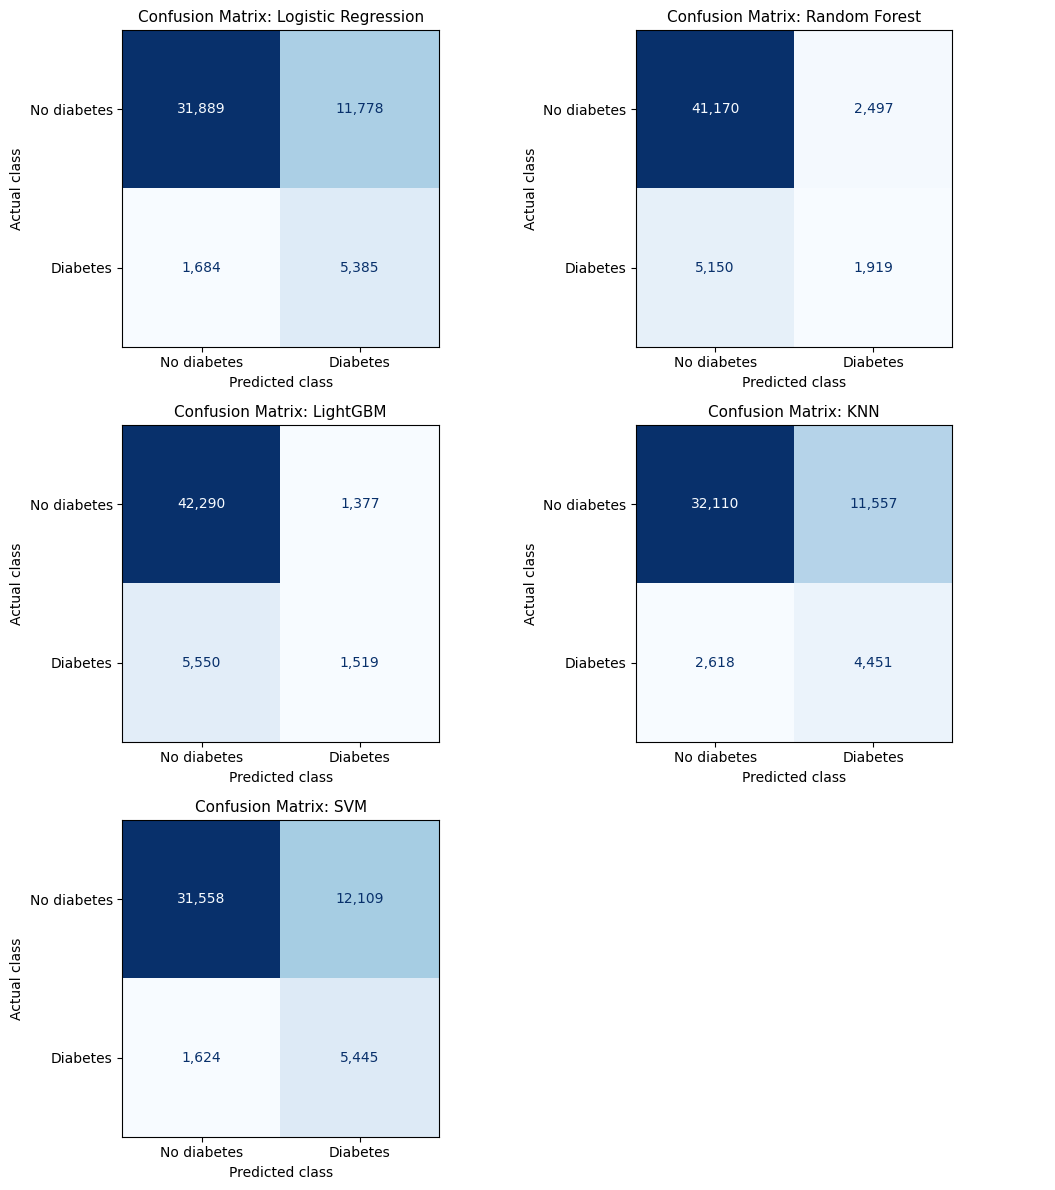

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

CLASS_LABELS = ["No diabetes", "Diabetes"]

def plot_confusion_matrices(model_dict, X, y, ax):
    y_pred = model_dict['model'].predict(X)
    cm = confusion_matrix(y, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_LABELS)
    disp.plot(cmap='Blues', ax=ax, colorbar=False, values_format=',d')
    ax.set_title(f"Confusion Matrix: {model_dict['Model Name']}", fontsize=11)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

models = [
    {'Model Name': 'Logistic Regression', 'model': logisticRegression_model},
    {'Model Name': 'Random Forest', 'model': randomForest_model},
    {'Model Name': 'LightGBM', 'model': lightGBM_model},
    {'Model Name': 'KNN', 'model': knn_model},
    {'Model Name': 'SVM', 'model': svm_model}
]

fig, axes = plt.subplots(3, 2, figsize=(11, 12))
axes_flat = axes.flatten()

for i, model in enumerate(models):
    plot_confusion_matrices(model, X_test_scaled, y_test, ax=axes_flat[i])

axes_flat[-1].axis('off')
plt.tight_layout()
plt.show()

*Figure 9. Confusion matrices of all models on the test set.*

The rows show the true class and the columns show the predicted class. For diabetes screening, the most important cells are the false negatives in the lower-left corner, because they are the people who actually have diabetes but were missed by the model.

The confusion matrices show a clear trade-off: models with higher recall such as Logistic Regression and SVM find more diabetes cases, but they also produce more false positives. In imbalanced data, I compare the positive-class performance in the bottom row, not just the overall accuracy.

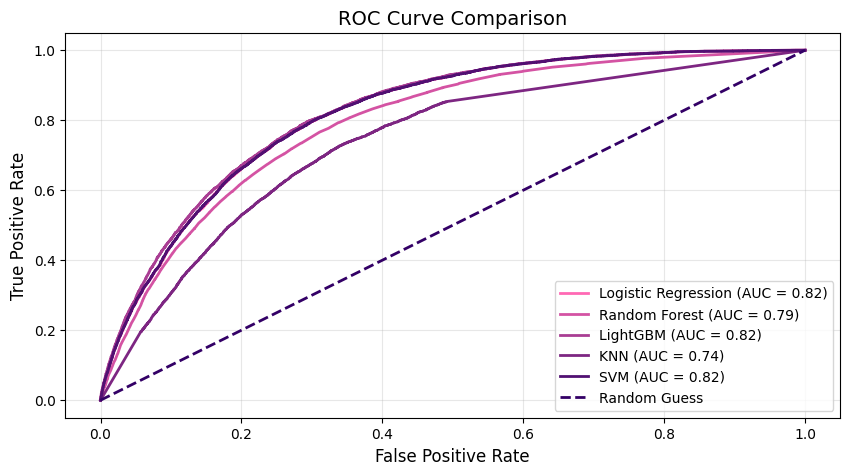

In [27]:
# Plotting ROC Curves

# ROC-AUC Curve for all models

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

start_color = "#FF69B4"  # HotPink
end_color = "#330066"

cmap = mcolors.LinearSegmentedColormap.from_list(
    "pink_to_purple", [start_color, end_color]
)

n_models = len(evaluation_results)

plt.figure(figsize=(10, 5))

for i, row in enumerate(evaluation_results.to_dict("records")):
    color_val = (i / (n_models - 1) * 0.85) if n_models > 1 else 0
    color = cmap(color_val)

    plt.plot(
        row["FPR"],
        row["TPR"],
        label=f"{row['Model Name']} (AUC = {row['ROC-AUC Score']:.2f})",
        color=color,
        lw=2,
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Guess", lw=2, color=end_color)

plt.title("ROC Curve Comparison", fontsize=14)
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()


*Figure 10. ROC curves of all models.*

The ROC curve shows the trade-off between the true positive rate and the false positive rate across different decision thresholds. A curve closer to the upper-left corner and a higher AUC indicate better ranking performance, while the dashed line is the random baseline.

In this run, Logistic Regression and SVM are very close at ROC-AUC 0.820, LightGBM is slightly higher at 0.825, and Random Forest is lower at 0.795. KNN is the weakest in this ranking comparison with ROC-AUC 0.738.

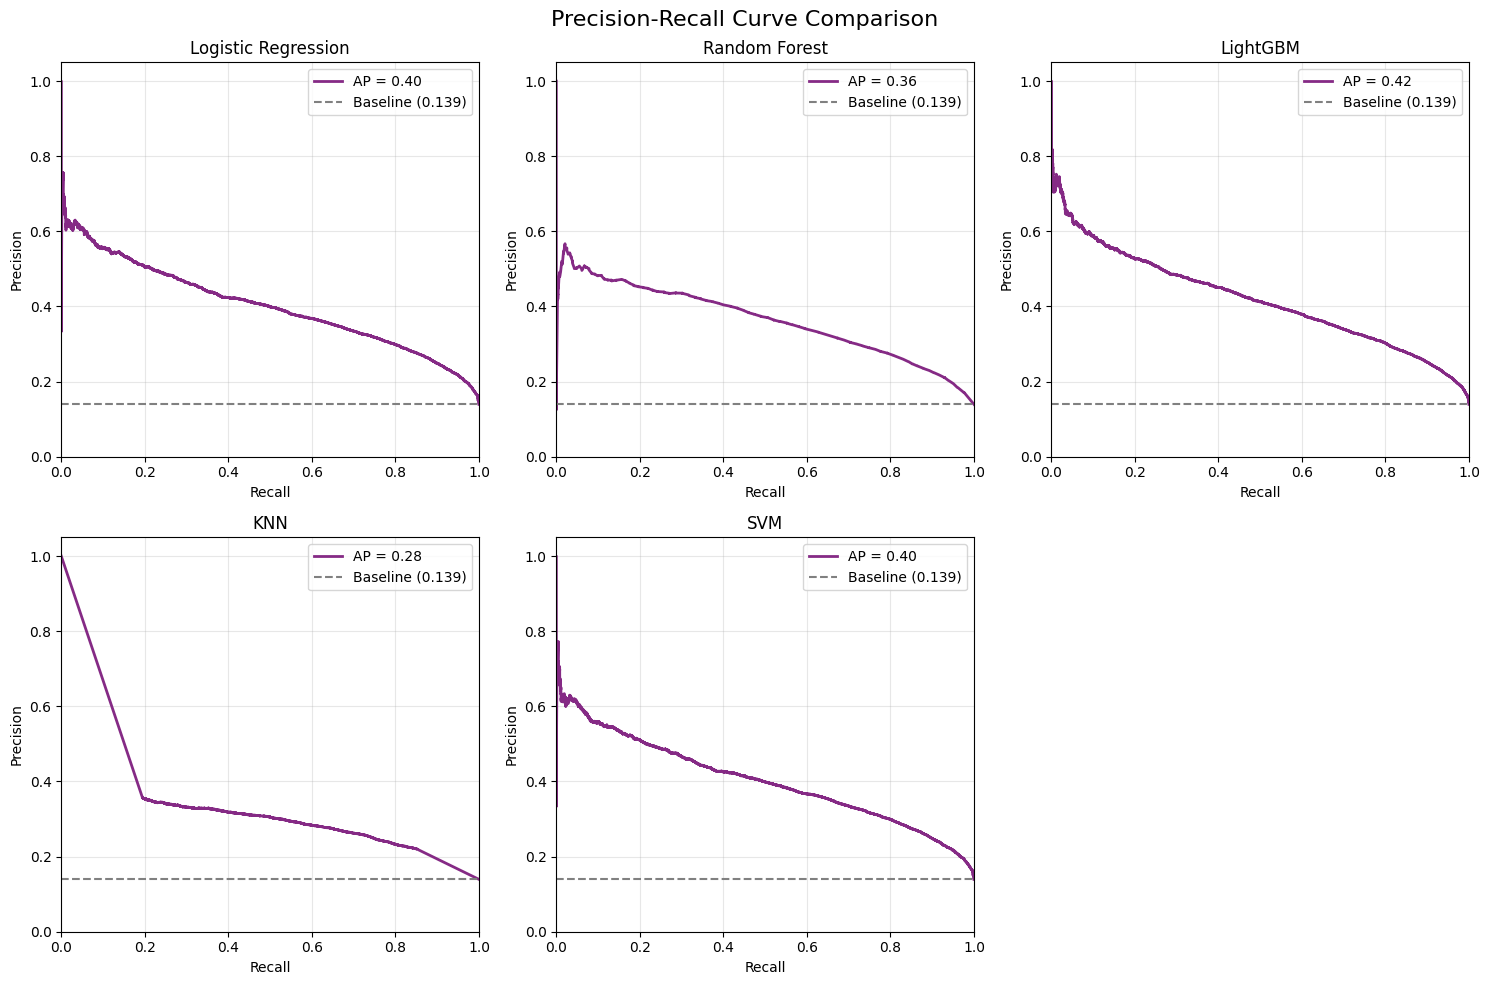

In [32]:
# PR-AUC Curve for all models

n_models = len(evaluation_results)
n_cols = 3
n_rows = (n_models + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 5 * n_rows)
)

axes = np.array(axes).flatten()

for i, model in enumerate(evaluation_results.to_dict("records")):
    ax = axes[i]

    precision, recall, _ = model["Precision-Recall Curve"]

    ax.plot(
        recall,
        precision,
        color=cmap(0.6),
        lw=2,
        label=f"AP = {model['Average Precision']:.2f}"
    )

    ax.axhline(
        y_test.mean(),
        color="gray",
        linestyle="--",
        label=f"Baseline ({y_test.mean():.3f})"
    )

    ax.set_title(model["Model Name"], fontsize=12)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)

# Hide unused subplot axes
for j in range(n_models, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Precision-Recall Curve Comparison", fontsize=16)
plt.tight_layout()
plt.show()

*Figure 11. Precision-Recall curves of all models.*

The precision-recall curve is more useful than ROC here because the positive class is the minority class. The baseline PR score is the positive rate, which is about 0.139, so any curve above this line is doing better than random guessing.

LightGBM has the best PR-AUC in this run at 0.418, followed closely by Logistic Regression and SVM at 0.402. Random Forest is lower at 0.361, and KNN is the weakest at 0.284. This matches the practical view that LightGBM is strongest at ranking positive cases, while the higher-recall models still suffer from extra false alarms.

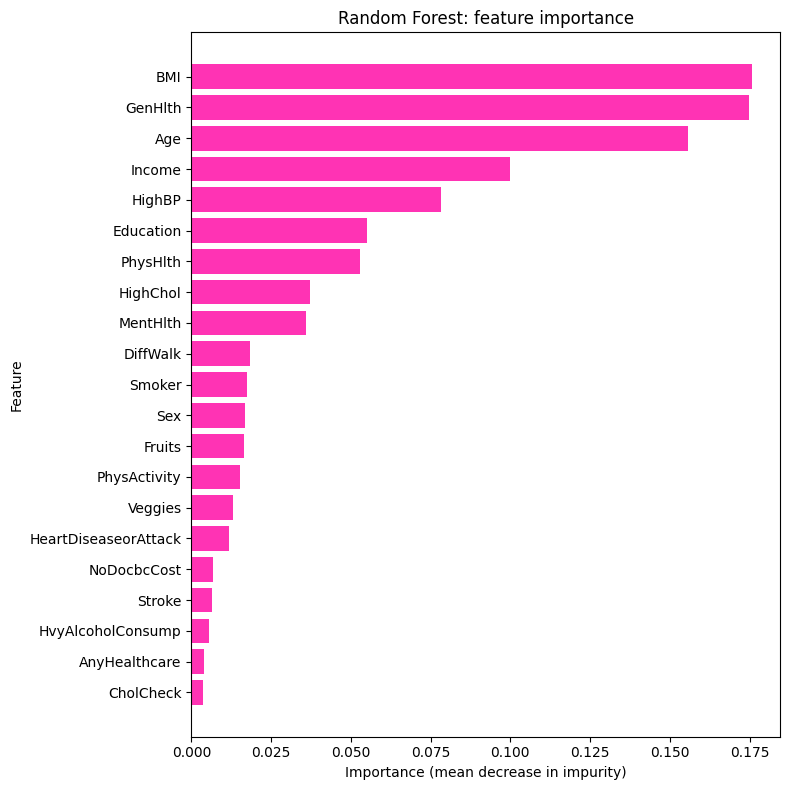

In [29]:
rf_imp = pd.Series(randomForest_model.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 8))
plt.barh(rf_imp.index, rf_imp.values, color=PALETTE[1])
plt.title("Random Forest: feature importance")
plt.xlabel("Importance (mean decrease in impurity)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

*Figure 12. Random Forest feature importance.*

This plot shows which features contributed most to the split decisions in the Random Forest model. `BMI`, `GenHlth`, and `Age` are the most important features, followed by `Income` and `HighBP`; this mostly agrees with the EDA, where poor general health, older age, higher BMI, and high blood pressure are linked to diabetes. `Income` and `Education` also rank fairly high even though they looked like weaker signals in the EDA. I also need to be careful with this type of importance: impurity importance can give a boost to variables with many possible values, so numeric variables like `BMI`, `MentHlth`, and `PhysHlth` can look more important than they really are in a purely ranking sense.

## Discussion and Conclusion

| Model | Accuracy | Precision | Recall | F1 | PR-AUC | ROC-AUC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.735 | 0.314 | 0.762 | 0.444 | 0.402 | 0.820 |
| Random Forest | 0.849 | 0.435 | 0.271 | 0.334 | 0.361 | 0.795 |
| LightGBM | 0.863 | 0.525 | 0.215 | 0.305 | 0.418 | 0.825 |
| KNN | 0.721 | 0.278 | 0.630 | 0.386 | 0.284 | 0.738 |
| SVM (LinearSVC) | 0.729 | 0.310 | 0.770 | 0.442 | 0.402 | 0.820 |

I used the same preprocessing and SMOTE-resampled training set for every model, and I evaluated them on the untouched imbalanced test set. The comparison shows a real trade-off: LightGBM has the best ranking metrics and the highest precision, but it has the lowest recall; Logistic Regression and SVM recover the most diabetes cases, with recall around 0.76 to 0.77, but they also create more false alarms. Random Forest and LightGBM are conservative at the default 0.5 threshold (low recall, higher precision). KNN is different: its recall is 0.630, but it has the lowest precision (0.278) and the lowest PR-AUC (0.284) and ROC-AUC (0.738), so it is the weakest model for ranking positive cases.

The key insight is that no model is uniformly “best” for every cost. If missing a sick person is much more expensive than a false alarm, I would choose SVM or Logistic Regression because they find the most true diabetes cases. If false alarms are more costly and the first goal is to rank high-risk respondents well, LightGBM is stronger because it has the best ROC-AUC, PR-AUC, and precision. I would not choose a model only on accuracy because a model that predicts “no diabetes” for everyone would still look good on this dataset.

There are several important limitations in this notebook. I used only a single train/test split, so I did not do cross-validation. There was no hyperparameter tuning, the threshold stayed fixed at 0.5, and SMOTE was applied to binary and ordinal variables even though synthetic values can become non-integer. There were also 24,206 duplicated rows (9.54%), which could appear in both train and test, and the data are cross-sectional survey records, so the results show association rather than causation.

The EDA showed that older age, worse self-rated health, higher BMI, higher blood pressure, and several chronic-health indicators are strongly related to diabetes. The feature importance plot agrees with that story: `BMI`, `GenHlth`, `Age`, `Income`, and `HighBP` stand out as important contributors. Overall, the notebook shows that the class imbalance is a central part of the problem, and the best model depends on whether the priority is recall or precision.